# Карты внимания и кластеризация DBSCAN

Сравнение моделей внимания (UNISAL, UNISAL 384x224, DeepGaze IIE) и подбор параметров DBSCAN.

In [6]:
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import DBSCAN
from IPython.display import display

sys.path.append("..")

from src.paths import BASE_DIR
from src.geometry import ViewingGeometry
from src.foveation.retina import load_retina_biology
from src.utils.converter import ImageConverter
from src.keypoints.saliency.unisal_model import load_unisal_model, predict_unisal_attention
from src.keypoints.saliency.deepgaze_model import load_deepgaze_iie_model, predict_deepgaze_iie

plt.rcParams['figure.figsize'] = (18, 6)
plt.rcParams['font.size'] = 10

geometry = ViewingGeometry(view_dist_mm=600.0, l_min=0.1, l_max=300.0)
retina = load_retina_biology()
converter = ImageConverter(L_MIN=geometry.l_min, L_MAX=geometry.l_max)

m_unisal = load_unisal_model(device="cpu")
m_iie = load_deepgaze_iie_model(device="cpu")

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png"}
EXAMPLE_IMAGES = sorted([
    p for p in (BASE_DIR / "examples").iterdir()
    if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
])

c:\Users\Misha_Savinov\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Misha_Savinov\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Loaded pretrained weights for efficientnet-b5


Using cache found in C:\Users\Misha_Savinov/.cache\torch\hub\pytorch_vision_v0.6.0
c:\Users\Misha_Savinov\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet201_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet201_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Using cache found in C:\Users\Misha_Savinov/.cache\torch\hub\pytorch_vision_v0.6.0
c:\Users\Misha_Savinov\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNeXt50_32X4D_Weights.IMAGENET1K_V1`. You can also use `weights=ResNeXt50_32X4D_

## 1. Сравнение моделей внимания

In [7]:
def run_experiment_1(img_path_input):
    img_path = Path(img_path_input)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print(f"Ошибка загрузки файла: {img_path}")
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    h, w = img_rgb.shape[:2]
    lum_map = converter.RGB_to_xyzL(img_rgb)[..., 3]
    mean_lum = float(np.mean(lum_map))
    median_lum = float(np.median(lum_map))
    mean_gray = float(np.mean(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)))
    median_gray = float(np.median(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)))
    
    print(f"Изображение: {img_path.name} | Разрешение: {w}x{h} px")
    print(f"Средняя яркость: {mean_lum:.2f} кд/м² (sRGB: {mean_gray:.1f}) | Медианная яркость: {median_lum:.2f} кд/м² (sRGB: {median_gray:.1f})\n")
    
    heat_unisal_orig = predict_unisal_attention(img_rgb, m_unisal, resize=False)
    heat_unisal_small = predict_unisal_attention(img_rgb, m_unisal, resize=True)
    heat_iie_orig = predict_deepgaze_iie(img_rgb, m_iie)
    
    fig, axes = plt.subplots(1, 4, figsize=(24, 6), layout="constrained")
    
    axes[0].imshow(img_rgb)
    axes[0].set_title(f"Фото: {img_path.name}\n({w}x{h} px)", fontsize=11)
    axes[0].axis('off')
    
    im1 = axes[1].imshow(heat_unisal_orig, cmap="inferno", vmin=0.0, vmax=1.0)
    axes[1].set_title("UNISAL (оригинал)", fontsize=11)
    axes[1].axis('off')
    cbar1 = fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
    cbar1.set_label("Внимание", fontsize=10)
    
    im2 = axes[2].imshow(heat_unisal_small, cmap="inferno", vmin=0.0, vmax=1.0)
    axes[2].set_title("UNISAL (ресайз 384x224)", fontsize=11)
    axes[2].axis('off')
    cbar2 = fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
    cbar2.set_label("Внимание", fontsize=10)
    
    im3 = axes[3].imshow(heat_iie_orig, cmap="inferno", vmin=0.0, vmax=1.0)
    axes[3].set_title("DeepGaze IIE (оригинал)", fontsize=11)
    axes[3].axis('off')
    cbar3 = fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)
    cbar3.set_label("Внимание", fontsize=10)
    
    plt.show()
    plt.close('all')


Изображение: alenyshka.jpg | Разрешение: 1280x770 px
Средняя яркость: 41.41 кд/м² (sRGB: 91.0) | Медианная яркость: 25.05 кд/м² (sRGB: 79.0)



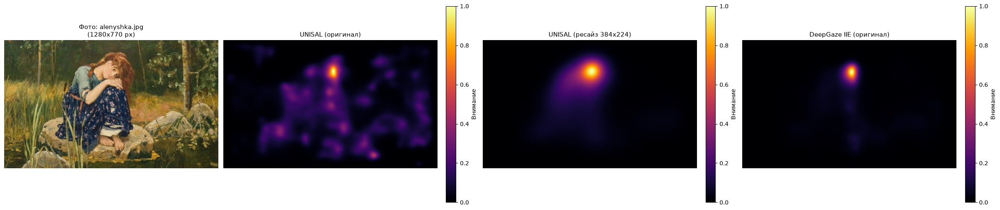

Изображение: br_joi.jpg | Разрешение: 1500x999 px
Средняя яркость: 21.80 кд/м² (sRGB: 62.0) | Медианная яркость: 12.98 кд/м² (sRGB: 58.0)



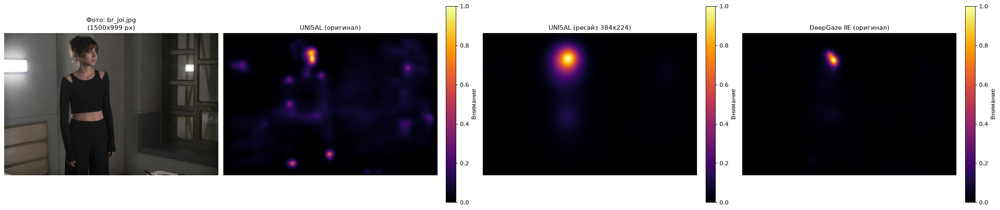

Изображение: landscape.jpg | Разрешение: 740x415 px
Средняя яркость: 43.59 кд/м² (sRGB: 89.9) | Медианная яркость: 26.98 кд/м² (sRGB: 82.0)



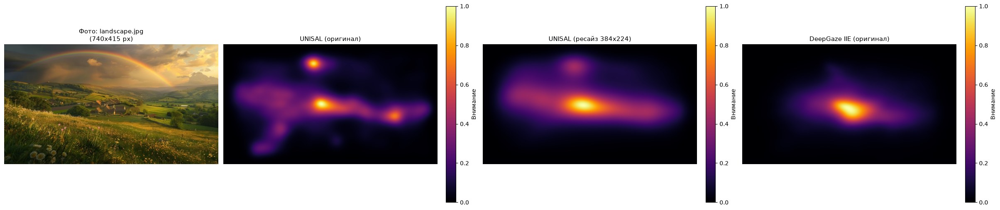

Изображение: photo_flower.jpg | Разрешение: 736x913 px
Средняя яркость: 39.48 кд/м² (sRGB: 85.5) | Медианная яркость: 23.95 кд/м² (sRGB: 78.0)



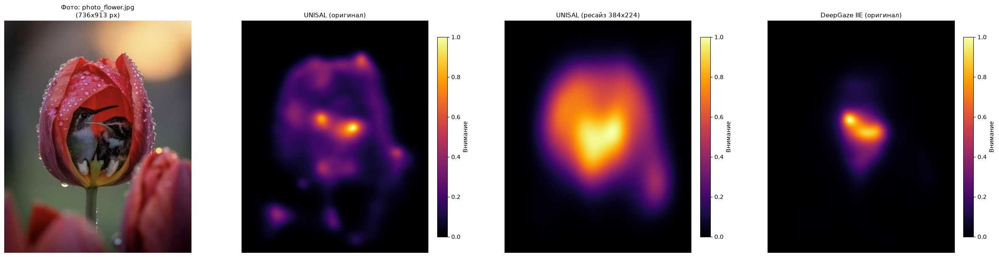

Изображение: photo_woman.jpg | Разрешение: 736x1098 px
Средняя яркость: 127.82 кд/м² (sRGB: 159.7) | Медианная яркость: 137.31 кд/м² (sRGB: 180.0)



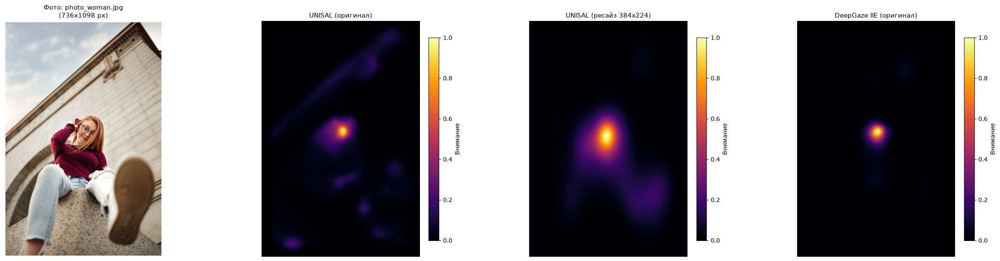

Изображение: Rosenblatt.jpg | Разрешение: 387x429 px
Средняя яркость: 33.05 кд/м² (sRGB: 69.1) | Медианная яркость: 8.29 кд/м² (sRGB: 46.0)



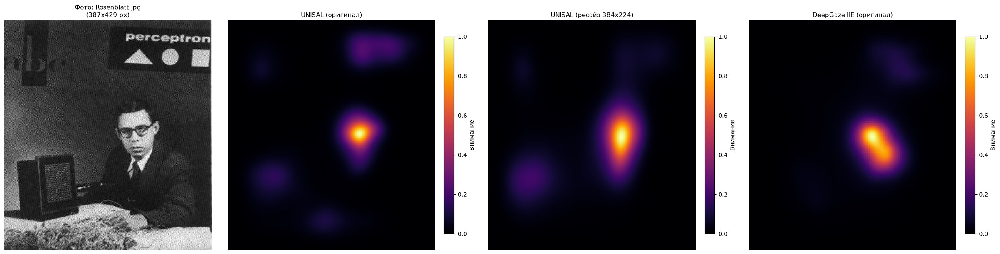

Изображение: tiger.jpg | Разрешение: 736x1104 px
Средняя яркость: 68.19 кд/м² (sRGB: 107.6) | Медианная яркость: 54.41 кд/м² (sRGB: 108.0)



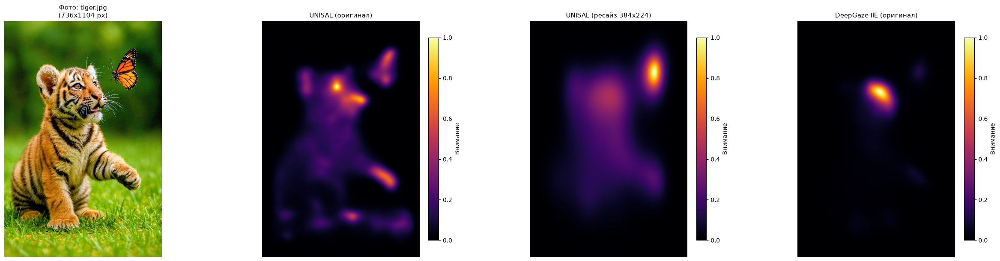

In [8]:
for img_path in EXAMPLE_IMAGES:
    run_experiment_1(img_path)


## 2. Сетка параметров DBSCAN

- Квантили внимания: топ-5%, топ-10%, топ-20% площади кадра
- Шаг связности: eps = 2.0, 4.0, 8.0 px
- Центры: X (белый) — взвешенный центр внимания, o (черный) — геометрический центр

In [9]:
def run_experiment_2(
    img_path_input,
    quantiles=(5, 10, 20),
    eps_list=(2.0, 4.0, 8.0),
    min_samples: int = 10
):
    img_path = Path(img_path_input)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print(f"Ошибка загрузки файла: {img_path}")
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    total_pixels = w * h
    
    print(f"Изображение: {img_path.name} | Разрешение: {w}x{h} px ({total_pixels:,} px)\n")
    
    heat_unisal_orig = predict_unisal_attention(img_rgb, m_unisal, resize=False)
    heat_unisal_small = predict_unisal_attention(img_rgb, m_unisal, resize=True)
    heat_iie_orig = predict_deepgaze_iie(img_rgb, m_iie)
    
    models = {
        'UNISAL (оригинал)': heat_unisal_orig,
        'UNISAL (ресайз 384x224)': heat_unisal_small,
        'DeepGaze IIE (оригинал)': heat_iie_orig
    }
    
    cmap_clusters = mpl.colormaps['tab20']
    
    for m_name, hmap in models.items():
        print(f'\n{m_name} — {img_path.name}:')
        
        fig, axes = plt.subplots(
            len(quantiles), len(eps_list),
            figsize=(7.5 * len(eps_list), 6.5 * len(quantiles)),
            layout="constrained"
        )
        if len(quantiles) == 1 and len(eps_list) == 1:
            axes = np.array([[axes]])
        elif len(quantiles) == 1:
            axes = np.expand_dims(axes, 0)
        elif len(eps_list) == 1:
            axes = np.expand_dims(axes, 1)
            
        summary_rows = []
        
        for row_idx, top_pct in enumerate(quantiles):
            q_th = float(np.percentile(hmap, 100 - top_pct))
            ys, xs = np.where(hmap >= q_th)
            n_selected = len(xs)
            n_background = total_pixels - n_selected
            
            points_full = np.column_stack([xs, ys])
            weights_full = hmap[ys, xs]
            
            stride = max(1, int(np.ceil(n_selected / 20000)))
            points = points_full[::stride]
            weights = weights_full[::stride]
            eff_min_samples = max(5, int(min_samples / stride))
            
            for col_idx, eps in enumerate(eps_list):
                ax = axes[row_idx, col_idx]
                ax.imshow(img_rgb)
                
                db = DBSCAN(eps=eps, min_samples=eff_min_samples).fit(points)
                labels = db.labels_
                unique_labels = sorted(list(set(labels)))
                
                cluster_labels = [k for k in unique_labels if k != -1]
                n_clusters = len(cluster_labels)
                noise_mask = (labels == -1)
                n_noise = int(np.sum(noise_mask)) * stride
                n_clustered = n_selected - n_noise
                
                cluster_info = []
                for k in cluster_labels:
                    mask = (labels == k)
                    c_size = int(np.sum(mask)) * stride
                    cluster_info.append((c_size, k, mask))
                cluster_info.sort(key=lambda x: x[0], reverse=True)
                
                other_count = max(0, len(cluster_info) - 5)
                cluster_sizes = [ci[0] for ci in cluster_info]
                
                for rank, (c_size, k, mask) in enumerate(cluster_info):
                    c_pts = points[mask]
                    c_weights = weights[mask]
                    color = cmap_clusters(k % 20)
                    
                    lbl = f"К{rank+1} ({c_size:,} px)" if rank < 5 else None
                    ax.scatter(c_pts[:, 0], c_pts[:, 1], color=color, s=8, alpha=0.6, label=lbl)
                    
                    tw = np.sum(c_weights)
                    cx_w = np.sum(c_pts[:, 0] * c_weights) / tw
                    cy_w = np.sum(c_pts[:, 1] * c_weights) / tw
                    
                    cx_g = float(np.mean(c_pts[:, 0]))
                    cy_g = float(np.mean(c_pts[:, 1]))
                    
                    ax.scatter(cx_g, cy_g, c='black', marker='o', s=25, zorder=5)
                    ax.scatter(cx_w, cy_w, c='white', edgecolors='black', marker='X', s=55, zorder=6)
                    
                if other_count > 0:
                    ax.scatter([], [], color='none', label=f"+ еще {other_count} мелких кл.")
                if n_noise > 0:
                    ax.scatter(points[noise_mask, 0], points[noise_mask, 1], c='gray', s=6, alpha=0.3, label=f"Шум ({n_noise:,} px)")
                    
                ax.scatter([], [], c='white', edgecolors='black', marker='X', s=45, label='Взвешенный центр')
                ax.scatter([], [], c='black', marker='o', s=20, label='Геом. центр')
                
                sizes_str = ", ".join(f"{s:,}" for s in cluster_sizes[:5])
                if len(cluster_sizes) > 5:
                    sizes_str += f" ... (+{len(cluster_sizes)-5})"
                    
                summary_rows.append({
                    'Модель': m_name,
                    'Топ внимания': f"{top_pct}%",
                    'Порог': round(q_th, 4),
                    'eps (px)': eps,
                    'Кластеров': n_clusters,
                    'Точек в кластерах': n_clustered,
                    'Шум': n_noise,
                    'Фон (отсечено)': n_background,
                    'Топ-5 размеров (px)': sizes_str if cluster_sizes else "-"
                })
                
                ax.set_title(f"{m_name} | Топ {top_pct}% (пор. {q_th:.3f}) | eps={eps} ({n_clusters} кл.)", fontsize=9.5)
                ax.axis('off')
                ax.legend(loc='lower right', fontsize=7.5, framealpha=0.85)
                
        plt.show()
        plt.close('all')
        
        df_summary = pd.DataFrame(summary_rows)
        display(df_summary)
        print()

Изображение: alenyshka.jpg | Разрешение: 1280x770 px (985,600 px)


UNISAL (оригинал) — alenyshka.jpg:


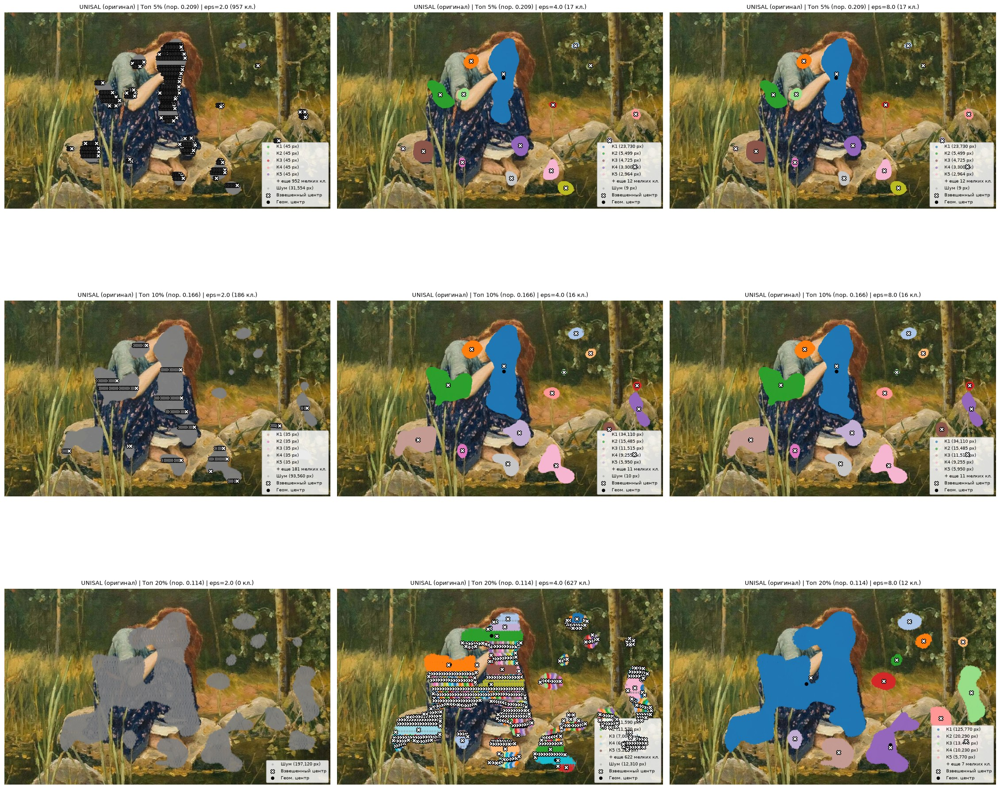

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (оригинал),5%,0.2095,2.0,957,17726,31554,936320,"45, 45, 45, 45, 45 ... (+952)"
1,UNISAL (оригинал),5%,0.2095,4.0,17,49271,9,936320,"23,730, 5,499, 4,725, 3,300, 2,964 ... (+12)"
2,UNISAL (оригинал),5%,0.2095,8.0,17,49271,9,936320,"23,730, 5,499, 4,725, 3,300, 2,964 ... (+12)"
3,UNISAL (оригинал),10%,0.1661,2.0,186,5000,93560,887040,"35, 35, 35, 35, 35 ... (+181)"
4,UNISAL (оригинал),10%,0.1661,4.0,16,98550,10,887040,"34,110, 15,485, 11,515, 9,255, 5,950 ... (+11)"
5,UNISAL (оригинал),10%,0.1661,8.0,16,98560,0,887040,"34,110, 15,485, 11,515, 9,255, 5,950 ... (+11)"
6,UNISAL (оригинал),20%,0.1145,2.0,0,0,197120,788480,-
7,UNISAL (оригинал),20%,0.1145,4.0,627,184810,12310,788480,"11,590, 11,570, 7,000, 6,340, 5,210 ... (+622)"
8,UNISAL (оригинал),20%,0.1145,8.0,12,197120,0,788480,"125,770, 20,290, 13,470, 10,230, 5,770 ... (+7)"




UNISAL (ресайз 384x224) — alenyshka.jpg:


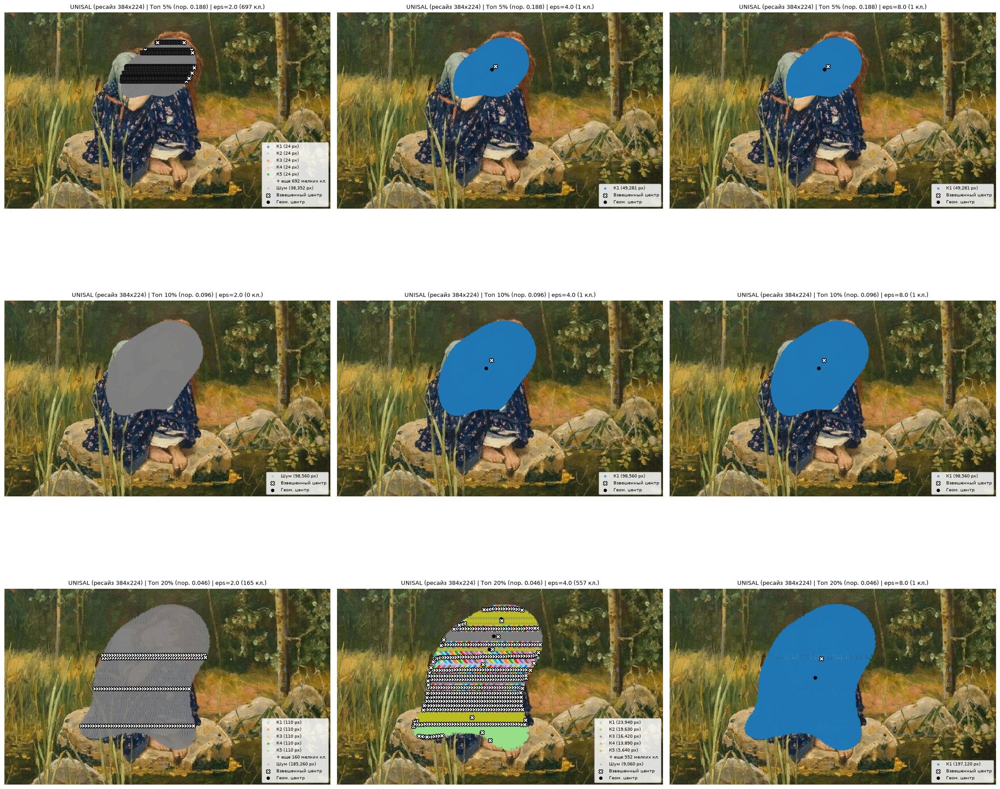

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (ресайз 384x224),5%,0.1878,2.0,697,10928,38352,936320,"24, 24, 24, 24, 24 ... (+692)"
1,UNISAL (ресайз 384x224),5%,0.1878,4.0,1,49280,0,936320,"49,281"
2,UNISAL (ресайз 384x224),5%,0.1878,8.0,1,49280,0,936320,"49,281"
3,UNISAL (ресайз 384x224),10%,0.0960,2.0,0,0,98560,887040,-
4,UNISAL (ресайз 384x224),10%,0.0960,4.0,1,98560,0,887040,"98,560"
5,UNISAL (ресайз 384x224),10%,0.0960,8.0,1,98560,0,887040,"98,560"
6,UNISAL (ресайз 384x224),20%,0.0457,2.0,165,11860,185260,788480,"110, 110, 110, 110, 110 ... (+160)"
7,UNISAL (ресайз 384x224),20%,0.0457,4.0,557,188060,9060,788480,"23,940, 19,630, 16,420, 13,890, 5,640 ... (+552)"
8,UNISAL (ресайз 384x224),20%,0.0457,8.0,1,197120,0,788480,"197,120"




DeepGaze IIE (оригинал) — alenyshka.jpg:


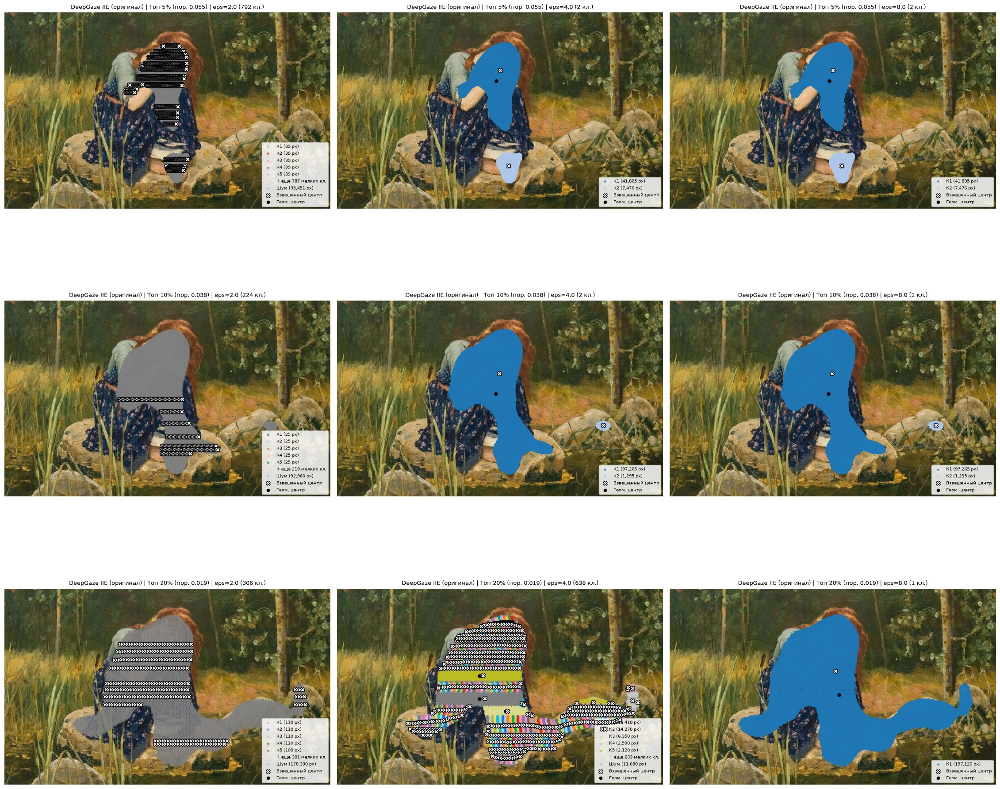

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,DeepGaze IIE (оригинал),5%,0.0551,2.0,792,13829,35451,936320,"39, 39, 39, 39, 39 ... (+787)"
1,DeepGaze IIE (оригинал),5%,0.0551,4.0,2,49280,0,936320,"41,805, 7,476"
2,DeepGaze IIE (оригинал),5%,0.0551,8.0,2,49280,0,936320,"41,805, 7,476"
3,DeepGaze IIE (оригинал),10%,0.0377,2.0,224,5600,92960,887040,"25, 25, 25, 25, 25 ... (+219)"
4,DeepGaze IIE (оригинал),10%,0.0377,4.0,2,98560,0,887040,"97,265, 1,295"
5,DeepGaze IIE (оригинал),10%,0.0377,8.0,2,98560,0,887040,"97,265, 1,295"
6,DeepGaze IIE (оригинал),20%,0.0192,2.0,306,18790,178330,788480,"110, 110, 110, 110, 100 ... (+301)"
7,DeepGaze IIE (оригинал),20%,0.0192,4.0,638,185430,11690,788480,"18,410, 14,270, 6,350, 2,590, 2,120 ... (+633)"
8,DeepGaze IIE (оригинал),20%,0.0192,8.0,1,197120,0,788480,"197,120"



Изображение: br_joi.jpg | Разрешение: 1500x999 px (1,498,500 px)


UNISAL (оригинал) — br_joi.jpg:


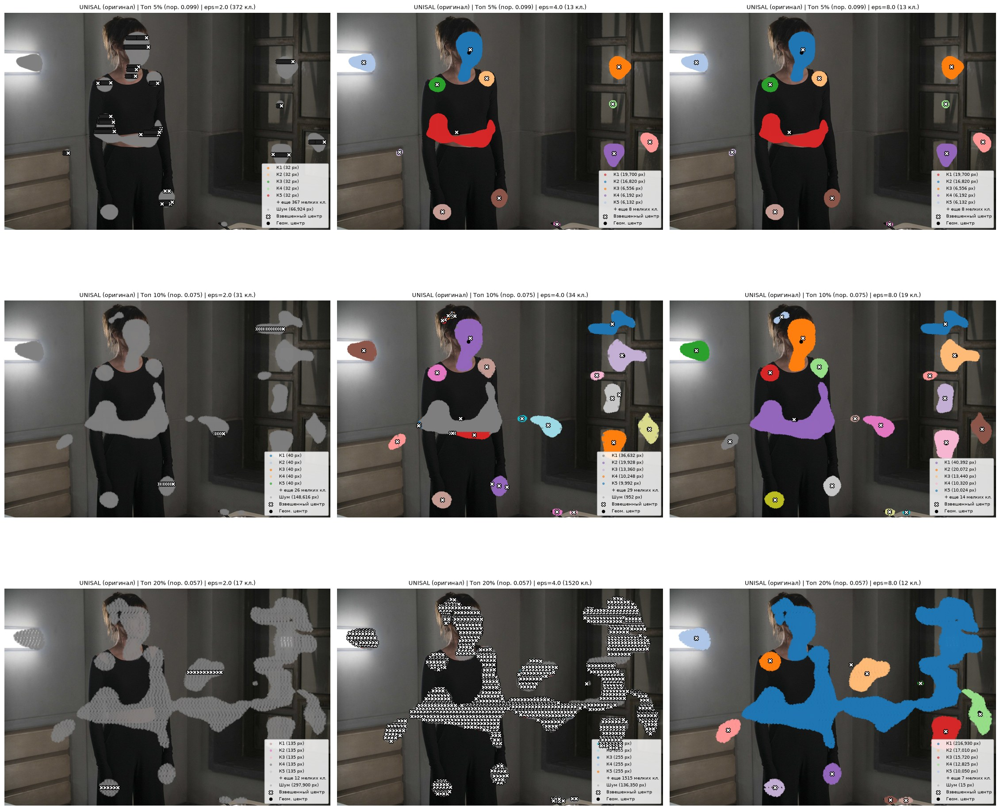

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (оригинал),5%,0.0988,2.0,372,8001,66924,1423575,"32, 32, 32, 32, 32 ... (+367)"
1,UNISAL (оригинал),5%,0.0988,4.0,13,74925,0,1423575,"19,700, 16,820, 6,556, 6,192, 6,132 ... (+8)"
2,UNISAL (оригинал),5%,0.0988,8.0,13,74925,0,1423575,"19,700, 16,820, 6,556, 6,192, 6,132 ... (+8)"
3,UNISAL (оригинал),10%,0.0753,2.0,31,1234,148616,1348650,"40, 40, 40, 40, 40 ... (+26)"
4,UNISAL (оригинал),10%,0.0753,4.0,34,148898,952,1348650,"36,632, 19,928, 13,360, 10,248, 9,992 ... (+29)"
5,UNISAL (оригинал),10%,0.0753,8.0,19,149850,0,1348650,"40,392, 20,072, 13,440, 10,320, 10,024 ... (+14)"
6,UNISAL (оригинал),20%,0.0574,2.0,17,1800,297900,1198800,"135, 135, 135, 135, 135 ... (+12)"
7,UNISAL (оригинал),20%,0.0574,4.0,1520,163350,136350,1198800,"270, 255, 255, 255, 255 ... (+1515)"
8,UNISAL (оригинал),20%,0.0574,8.0,12,299685,15,1198800,"216,930, 17,010, 15,720, 12,825, 10,050 ... (+7)"




UNISAL (ресайз 384x224) — br_joi.jpg:


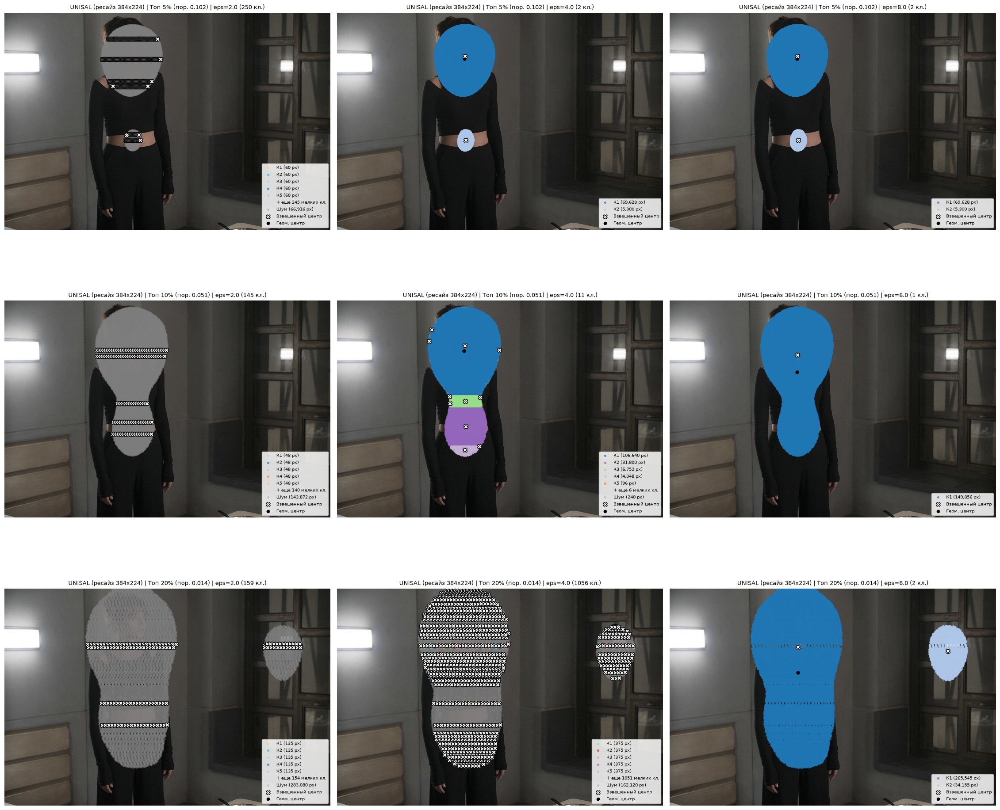

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (ресайз 384x224),5%,0.1020,2.0,250,8009,66916,1423575,"60, 60, 60, 60, 60 ... (+245)"
1,UNISAL (ресайз 384x224),5%,0.1020,4.0,2,74925,0,1423575,"69,628, 5,300"
2,UNISAL (ресайз 384x224),5%,0.1020,8.0,2,74925,0,1423575,"69,628, 5,300"
3,UNISAL (ресайз 384x224),10%,0.0506,2.0,145,5978,143872,1348650,"48, 48, 48, 48, 48 ... (+140)"
4,UNISAL (ресайз 384x224),10%,0.0506,4.0,11,149610,240,1348650,"106,640, 31,800, 6,752, 4,048, 96 ... (+6)"
5,UNISAL (ресайз 384x224),10%,0.0506,8.0,1,149850,0,1348650,"149,856"
6,UNISAL (ресайз 384x224),20%,0.0141,2.0,159,16620,283080,1198800,"135, 135, 135, 135, 135 ... (+154)"
7,UNISAL (ресайз 384x224),20%,0.0141,4.0,1056,137580,162120,1198800,"375, 375, 375, 375, 375 ... (+1051)"
8,UNISAL (ресайз 384x224),20%,0.0141,8.0,2,299700,0,1198800,"265,545, 34,155"




DeepGaze IIE (оригинал) — br_joi.jpg:


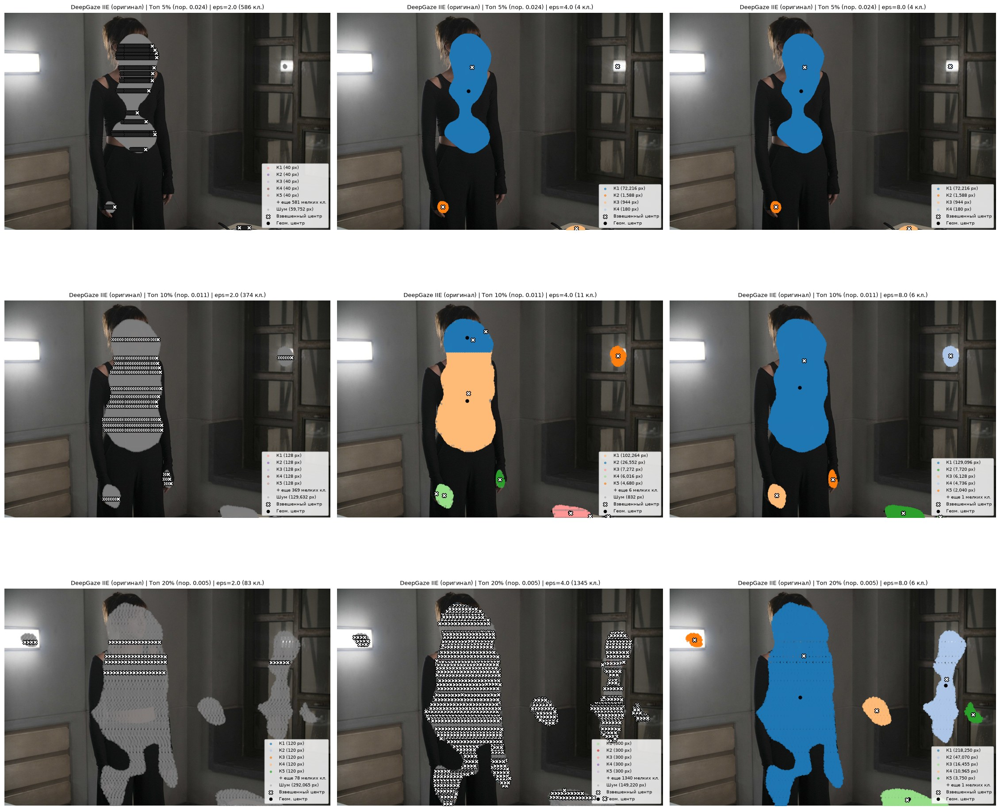

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,DeepGaze IIE (оригинал),5%,0.0240,2.0,586,15176,59752,1423572,"40, 40, 40, 40, 40 ... (+581)"
1,DeepGaze IIE (оригинал),5%,0.0240,4.0,4,74928,0,1423572,"72,216, 1,588, 944, 180"
2,DeepGaze IIE (оригинал),5%,0.0240,8.0,4,74928,0,1423572,"72,216, 1,588, 944, 180"
3,DeepGaze IIE (оригинал),10%,0.0109,2.0,374,20220,129632,1348648,"128, 128, 128, 128, 128 ... (+369)"
4,DeepGaze IIE (оригинал),10%,0.0109,4.0,11,149020,832,1348648,"102,264, 26,552, 7,272, 6,016, 4,680 ... (+6)"
5,DeepGaze IIE (оригинал),10%,0.0109,8.0,6,149852,0,1348648,"129,096, 7,720, 6,128, 4,736, 2,040 ... (+1)"
6,DeepGaze IIE (оригинал),20%,0.0050,2.0,83,7635,292065,1198800,"120, 120, 120, 120, 120 ... (+78)"
7,DeepGaze IIE (оригинал),20%,0.0050,4.0,1345,150480,149220,1198800,"300, 300, 300, 300, 300 ... (+1340)"
8,DeepGaze IIE (оригинал),20%,0.0050,8.0,6,299700,0,1198800,"218,250, 47,070, 16,455, 10,965, 3,750 ... (+1)"



Изображение: landscape.jpg | Разрешение: 740x415 px (307,100 px)


UNISAL (оригинал) — landscape.jpg:


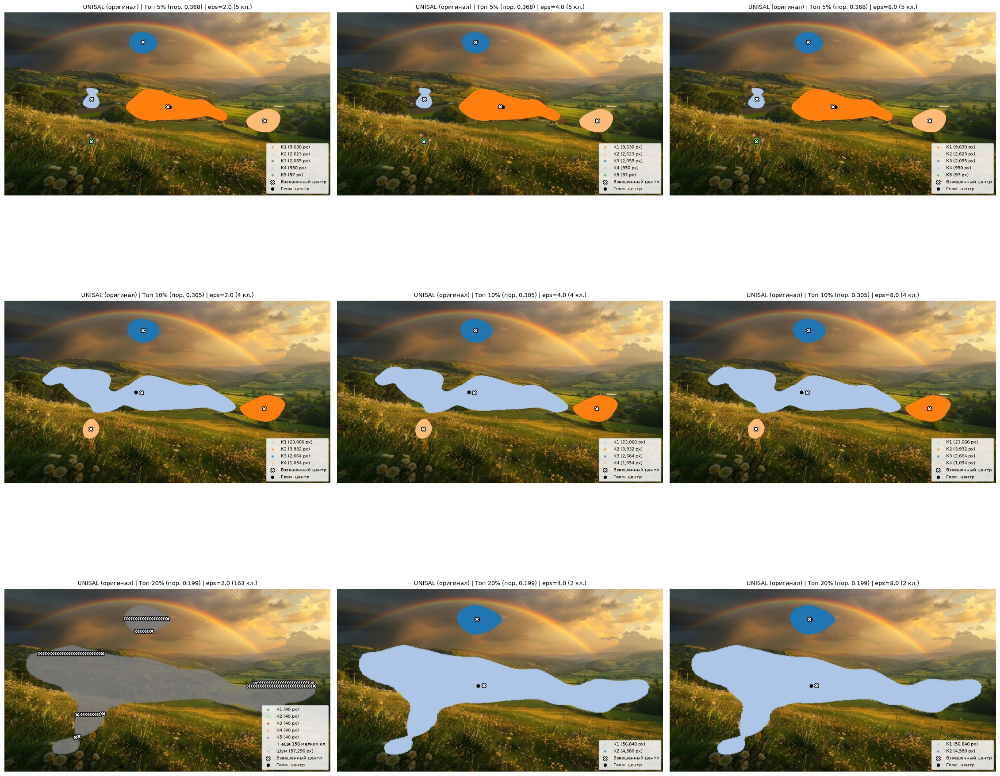

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (оригинал),5%,0.3685,2.0,5,15355,0,291745,"9,630, 2,623, 2,055, 950, 97"
1,UNISAL (оригинал),5%,0.3685,4.0,5,15355,0,291745,"9,630, 2,623, 2,055, 950, 97"
2,UNISAL (оригинал),5%,0.3685,8.0,5,15355,0,291745,"9,630, 2,623, 2,055, 950, 97"
3,UNISAL (оригинал),10%,0.3049,2.0,4,30710,0,276390,"23,060, 3,932, 2,664, 1,054"
4,UNISAL (оригинал),10%,0.3049,4.0,4,30710,0,276390,"23,060, 3,932, 2,664, 1,054"
5,UNISAL (оригинал),10%,0.3049,8.0,4,30710,0,276390,"23,060, 3,932, 2,664, 1,054"
6,UNISAL (оригинал),20%,0.1985,2.0,163,4124,57296,245680,"40, 40, 40, 40, 40 ... (+158)"
7,UNISAL (оригинал),20%,0.1985,4.0,2,61420,0,245680,"56,840, 4,580"
8,UNISAL (оригинал),20%,0.1985,8.0,2,61420,0,245680,"56,840, 4,580"




UNISAL (ресайз 384x224) — landscape.jpg:


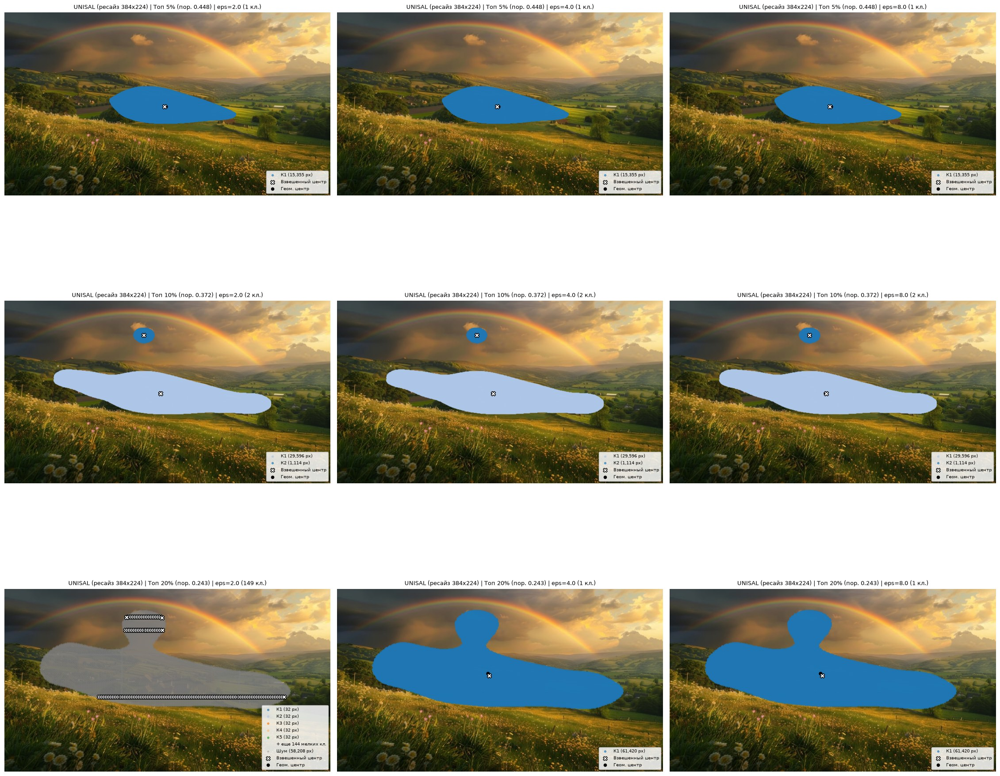

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (ресайз 384x224),5%,0.4476,2.0,1,15355,0,291745,"15,355"
1,UNISAL (ресайз 384x224),5%,0.4476,4.0,1,15355,0,291745,"15,355"
2,UNISAL (ресайз 384x224),5%,0.4476,8.0,1,15355,0,291745,"15,355"
3,UNISAL (ресайз 384x224),10%,0.3722,2.0,2,30710,0,276390,"29,596, 1,114"
4,UNISAL (ресайз 384x224),10%,0.3722,4.0,2,30710,0,276390,"29,596, 1,114"
5,UNISAL (ресайз 384x224),10%,0.3722,8.0,2,30710,0,276390,"29,596, 1,114"
6,UNISAL (ресайз 384x224),20%,0.2433,2.0,149,3212,58208,245680,"32, 32, 32, 32, 32 ... (+144)"
7,UNISAL (ресайз 384x224),20%,0.2433,4.0,1,61420,0,245680,"61,420"
8,UNISAL (ресайз 384x224),20%,0.2433,8.0,1,61420,0,245680,"61,420"




DeepGaze IIE (оригинал) — landscape.jpg:


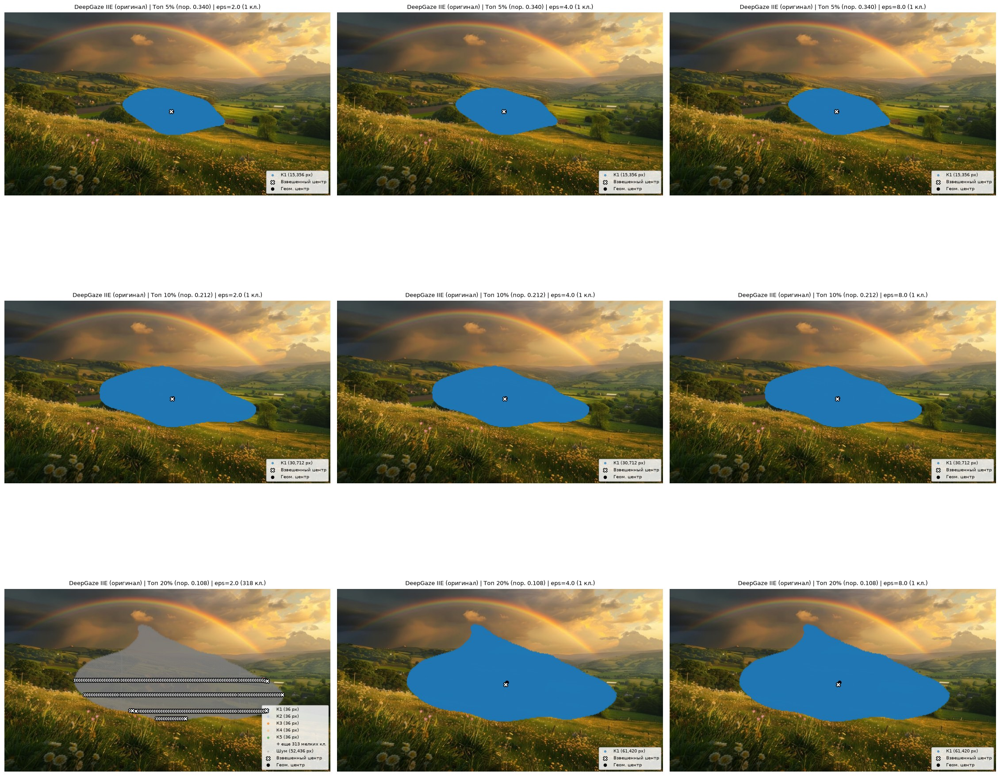

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,DeepGaze IIE (оригинал),5%,0.3402,2.0,1,15356,0,291744,"15,356"
1,DeepGaze IIE (оригинал),5%,0.3402,4.0,1,15356,0,291744,"15,356"
2,DeepGaze IIE (оригинал),5%,0.3402,8.0,1,15356,0,291744,"15,356"
3,DeepGaze IIE (оригинал),10%,0.2119,2.0,1,30712,0,276388,"30,712"
4,DeepGaze IIE (оригинал),10%,0.2119,4.0,1,30712,0,276388,"30,712"
5,DeepGaze IIE (оригинал),10%,0.2119,8.0,1,30712,0,276388,"30,712"
6,DeepGaze IIE (оригинал),20%,0.1079,2.0,318,8984,52436,245680,"36, 36, 36, 36, 36 ... (+313)"
7,DeepGaze IIE (оригинал),20%,0.1079,4.0,1,61420,0,245680,"61,420"
8,DeepGaze IIE (оригинал),20%,0.1079,8.0,1,61420,0,245680,"61,420"



Изображение: photo_flower.jpg | Разрешение: 736x913 px (671,968 px)


UNISAL (оригинал) — photo_flower.jpg:


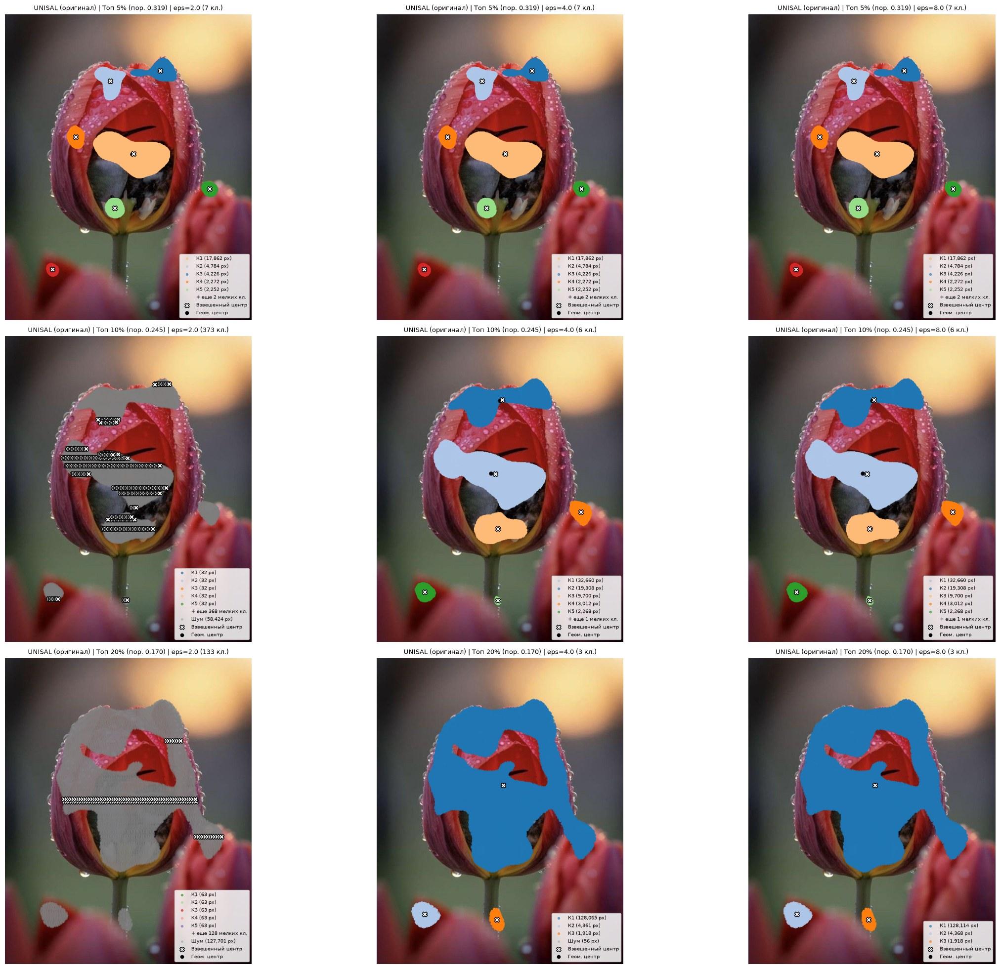

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (оригинал),5%,0.3192,2.0,7,33599,0,638369,"17,862, 4,784, 4,226, 2,272, 2,252 ... (+2)"
1,UNISAL (оригинал),5%,0.3192,4.0,7,33599,0,638369,"17,862, 4,784, 4,226, 2,272, 2,252 ... (+2)"
2,UNISAL (оригинал),5%,0.3192,8.0,7,33599,0,638369,"17,862, 4,784, 4,226, 2,272, 2,252 ... (+2)"
3,UNISAL (оригинал),10%,0.2449,2.0,373,8773,58424,604771,"32, 32, 32, 32, 32 ... (+368)"
4,UNISAL (оригинал),10%,0.2449,4.0,6,67197,0,604771,"32,660, 19,308, 9,700, 3,012, 2,268 ... (+1)"
5,UNISAL (оригинал),10%,0.2449,8.0,6,67197,0,604771,"32,660, 19,308, 9,700, 3,012, 2,268 ... (+1)"
6,UNISAL (оригинал),20%,0.1704,2.0,133,6693,127701,537574,"63, 63, 63, 63, 63 ... (+128)"
7,UNISAL (оригинал),20%,0.1704,4.0,3,134338,56,537574,"128,065, 4,361, 1,918"
8,UNISAL (оригинал),20%,0.1704,8.0,3,134394,0,537574,"128,114, 4,368, 1,918"




UNISAL (ресайз 384x224) — photo_flower.jpg:


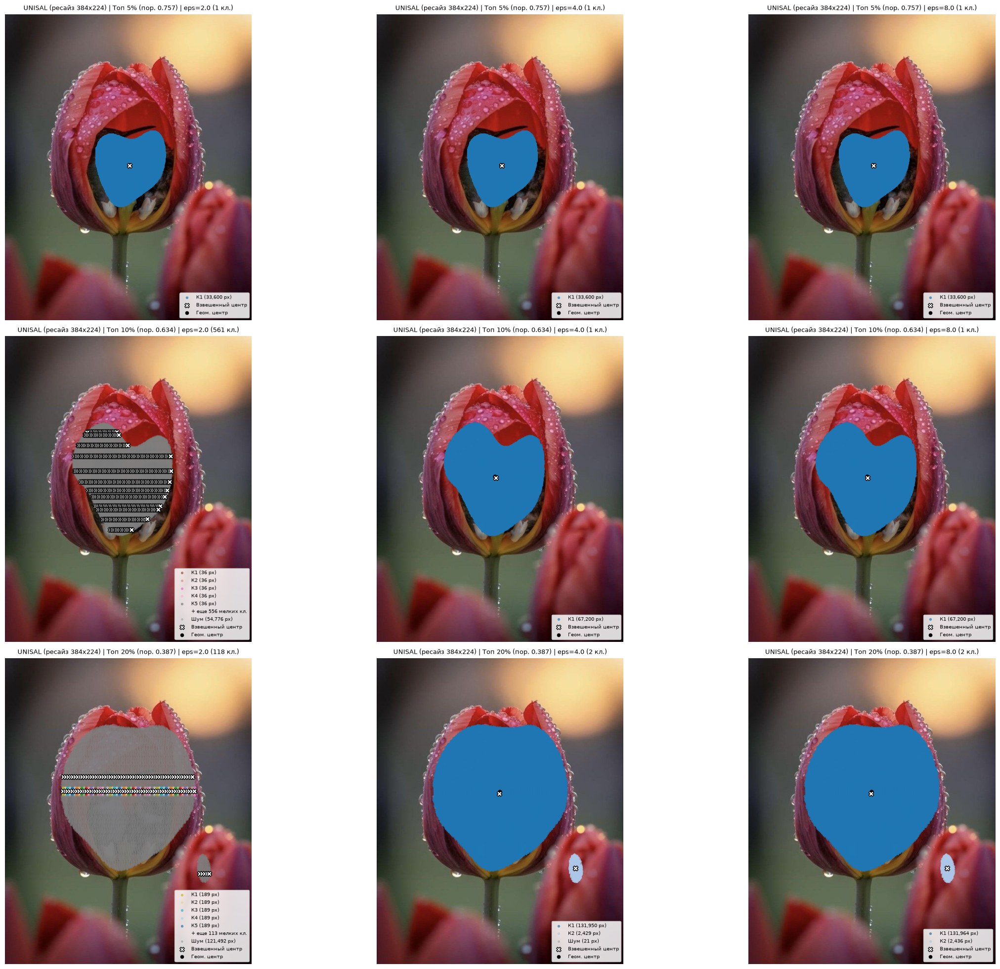

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (ресайз 384x224),5%,0.7573,2.0,1,33599,0,638369,"33,600"
1,UNISAL (ресайз 384x224),5%,0.7573,4.0,1,33599,0,638369,"33,600"
2,UNISAL (ресайз 384x224),5%,0.7573,8.0,1,33599,0,638369,"33,600"
3,UNISAL (ресайз 384x224),10%,0.6341,2.0,561,12421,54776,604771,"36, 36, 36, 36, 36 ... (+556)"
4,UNISAL (ресайз 384x224),10%,0.6341,4.0,1,67197,0,604771,"67,200"
5,UNISAL (ресайз 384x224),10%,0.6341,8.0,1,67197,0,604771,"67,200"
6,UNISAL (ресайз 384x224),20%,0.3873,2.0,118,12902,121492,537574,"189, 189, 189, 189, 189 ... (+113)"
7,UNISAL (ресайз 384x224),20%,0.3873,4.0,2,134373,21,537574,"131,950, 2,429"
8,UNISAL (ресайз 384x224),20%,0.3873,8.0,2,134394,0,537574,"131,964, 2,436"




DeepGaze IIE (оригинал) — photo_flower.jpg:


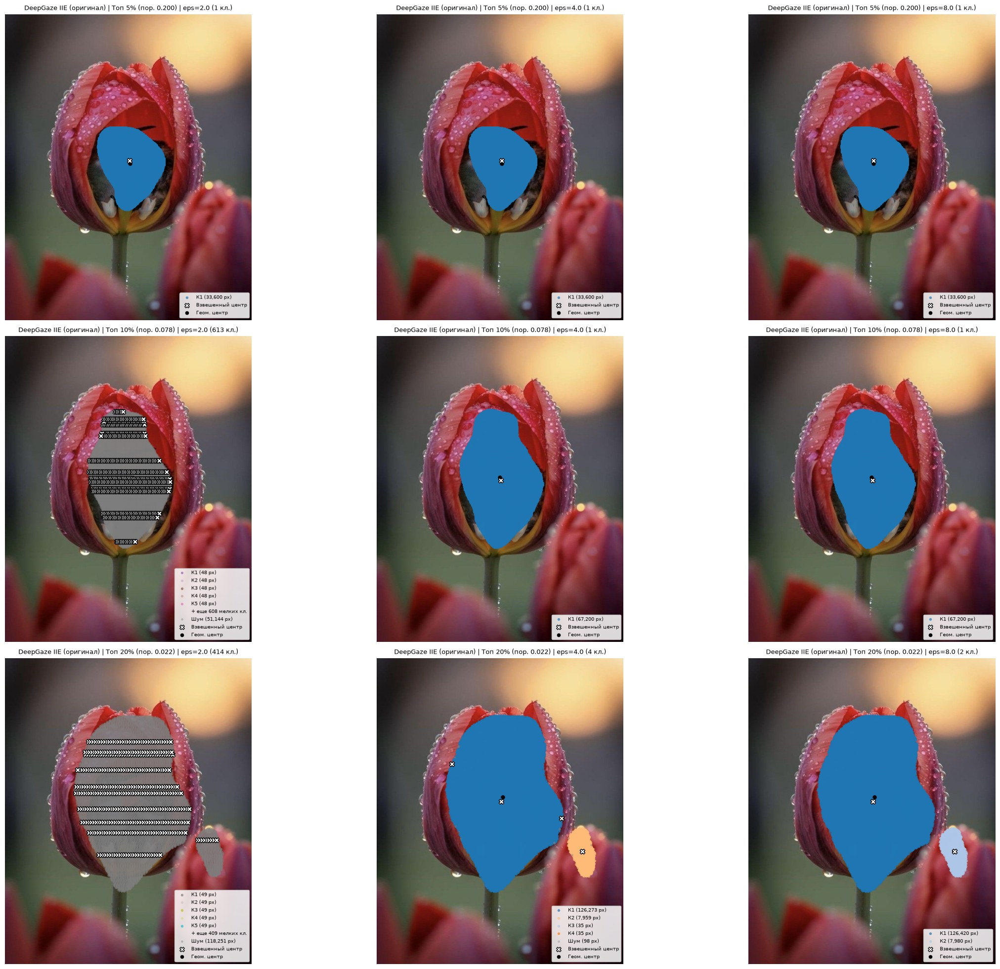

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,DeepGaze IIE (оригинал),5%,0.2003,2.0,1,33600,0,638368,"33,600"
1,DeepGaze IIE (оригинал),5%,0.2003,4.0,1,33600,0,638368,"33,600"
2,DeepGaze IIE (оригинал),5%,0.2003,8.0,1,33600,0,638368,"33,600"
3,DeepGaze IIE (оригинал),10%,0.0781,2.0,613,16056,51144,604768,"48, 48, 48, 48, 48 ... (+608)"
4,DeepGaze IIE (оригинал),10%,0.0781,4.0,1,67200,0,604768,"67,200"
5,DeepGaze IIE (оригинал),10%,0.0781,8.0,1,67200,0,604768,"67,200"
6,DeepGaze IIE (оригинал),20%,0.0221,2.0,414,16145,118251,537572,"49, 49, 49, 49, 49 ... (+409)"
7,DeepGaze IIE (оригинал),20%,0.0221,4.0,4,134298,98,537572,"126,273, 7,959, 35, 35"
8,DeepGaze IIE (оригинал),20%,0.0221,8.0,2,134396,0,537572,"126,420, 7,980"



Изображение: photo_woman.jpg | Разрешение: 736x1098 px (808,128 px)


UNISAL (оригинал) — photo_woman.jpg:


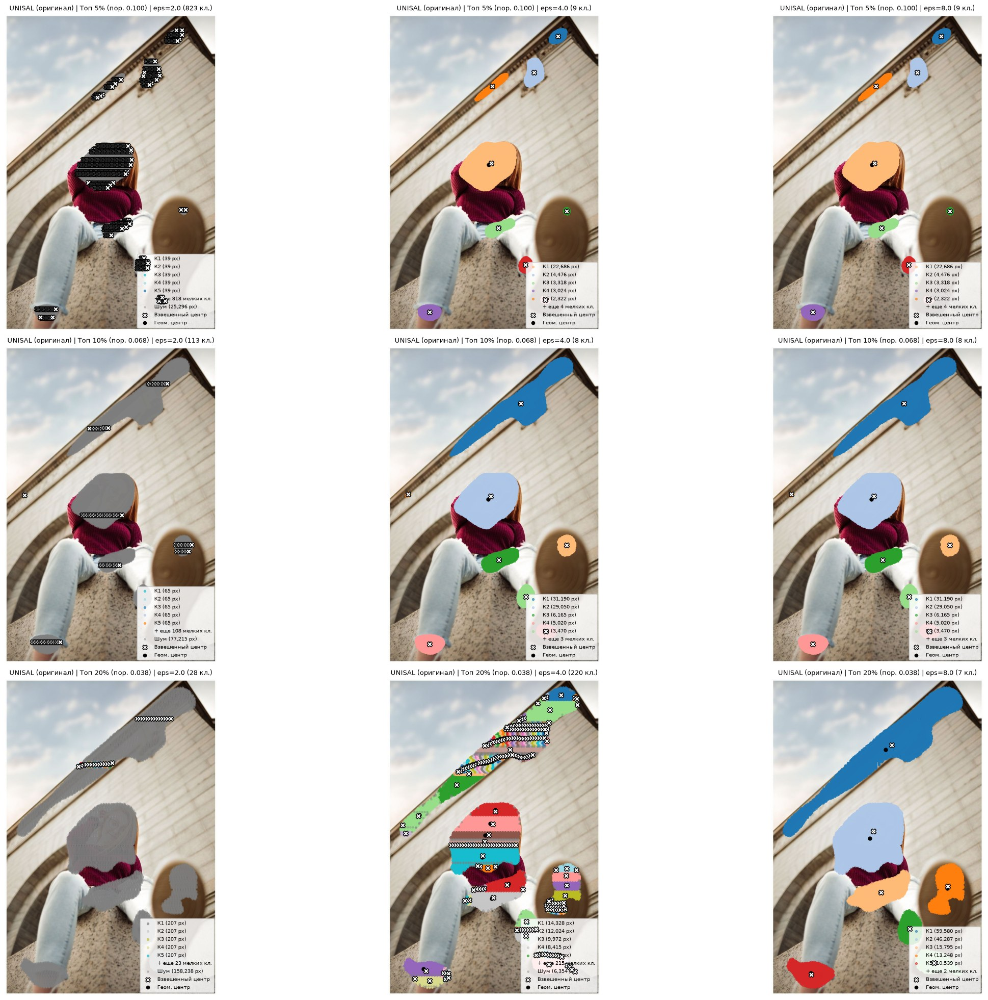

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (оригинал),5%,0.0998,2.0,823,15111,25296,767721,"39, 39, 39, 39, 39 ... (+818)"
1,UNISAL (оригинал),5%,0.0998,4.0,9,40407,0,767721,"22,686, 4,476, 3,318, 3,024, 2,322 ... (+4)"
2,UNISAL (оригинал),5%,0.0998,8.0,9,40407,0,767721,"22,686, 4,476, 3,318, 3,024, 2,322 ... (+4)"
3,UNISAL (оригинал),10%,0.0683,2.0,113,3598,77215,727315,"65, 65, 65, 65, 65 ... (+108)"
4,UNISAL (оригинал),10%,0.0683,4.0,8,80813,0,727315,"31,190, 29,050, 6,165, 5,020, 3,470 ... (+3)"
5,UNISAL (оригинал),10%,0.0683,8.0,8,80813,0,727315,"31,190, 29,050, 6,165, 5,020, 3,470 ... (+3)"
6,UNISAL (оригинал),20%,0.0380,2.0,28,3388,158238,646502,"207, 207, 207, 207, 207 ... (+23)"
7,UNISAL (оригинал),20%,0.0380,4.0,220,155272,6354,646502,"14,328, 12,024, 9,972, 8,415, 7,128 ... (+215)"
8,UNISAL (оригинал),20%,0.0380,8.0,7,161626,0,646502,"59,580, 46,287, 15,795, 13,248, 10,539 ... (+2)"




UNISAL (ресайз 384x224) — photo_woman.jpg:


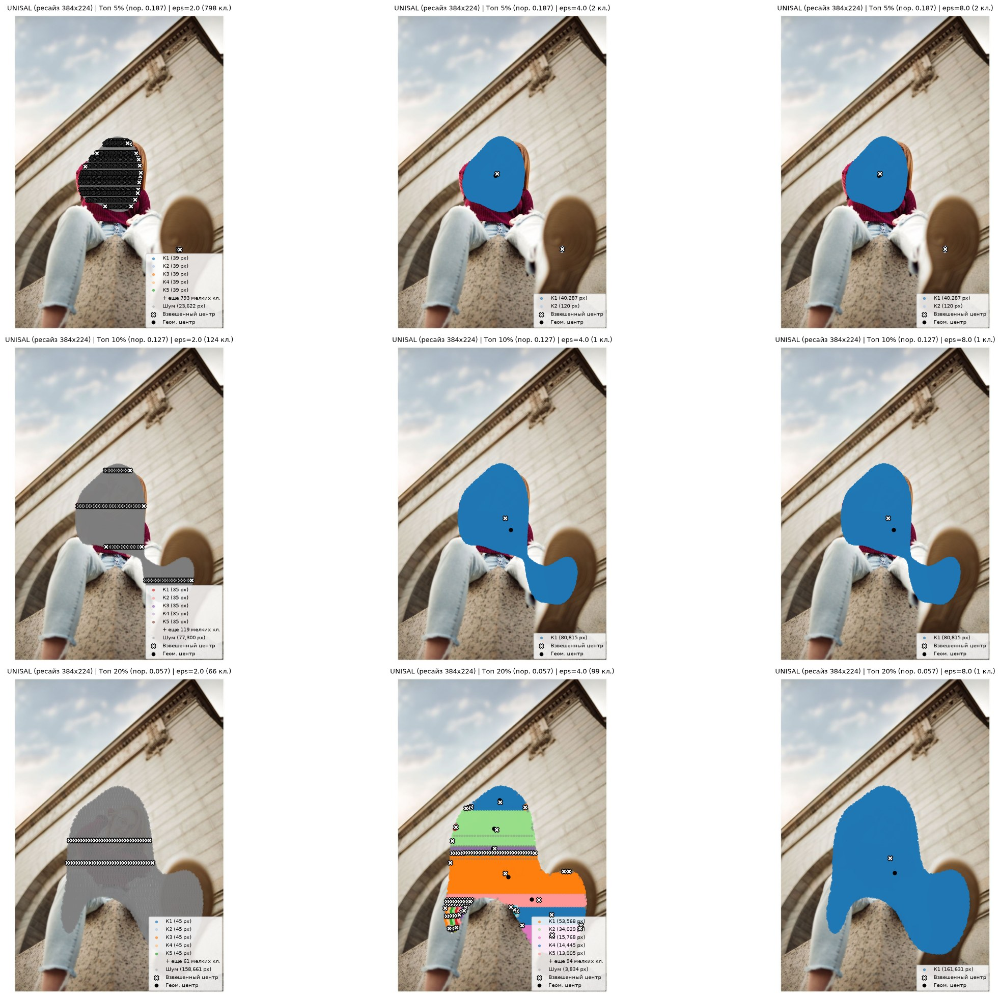

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (ресайз 384x224),5%,0.1872,2.0,798,16785,23622,767721,"39, 39, 39, 39, 39 ... (+793)"
1,UNISAL (ресайз 384x224),5%,0.1872,4.0,2,40407,0,767721,"40,287, 120"
2,UNISAL (ресайз 384x224),5%,0.1872,8.0,2,40407,0,767721,"40,287, 120"
3,UNISAL (ресайз 384x224),10%,0.1271,2.0,124,3513,77300,727315,"35, 35, 35, 35, 35 ... (+119)"
4,UNISAL (ресайз 384x224),10%,0.1271,4.0,1,80813,0,727315,"80,815"
5,UNISAL (ресайз 384x224),10%,0.1271,8.0,1,80813,0,727315,"80,815"
6,UNISAL (ресайз 384x224),20%,0.0566,2.0,66,2965,158661,646502,"45, 45, 45, 45, 45 ... (+61)"
7,UNISAL (ресайз 384x224),20%,0.0566,4.0,99,157792,3834,646502,"53,568, 34,029, 15,768, 14,445, 13,905 ... (+94)"
8,UNISAL (ресайз 384x224),20%,0.0566,8.0,1,161626,0,646502,"161,631"




DeepGaze IIE (оригинал) — photo_woman.jpg:


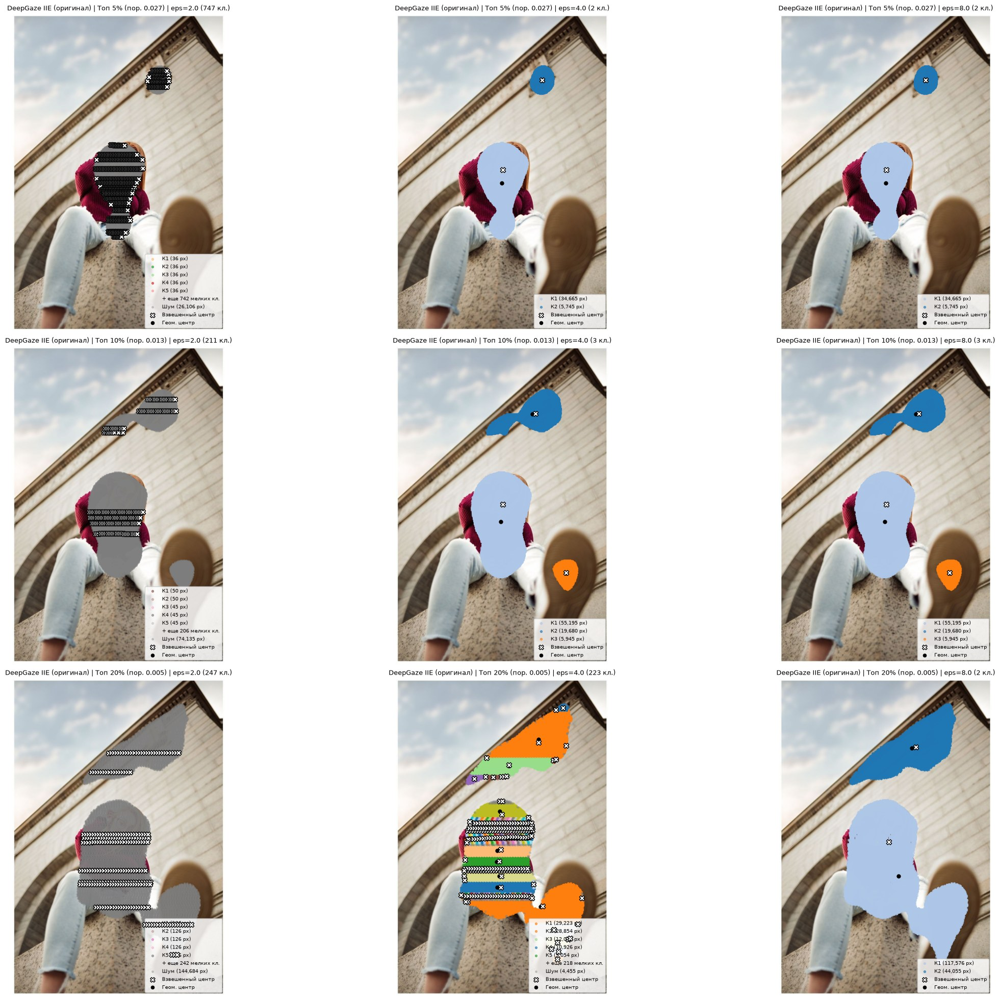

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,DeepGaze IIE (оригинал),5%,0.0273,2.0,747,14302,26106,767720,"36, 36, 36, 36, 36 ... (+742)"
1,DeepGaze IIE (оригинал),5%,0.0273,4.0,2,40408,0,767720,"34,665, 5,745"
2,DeepGaze IIE (оригинал),5%,0.0273,8.0,2,40408,0,767720,"34,665, 5,745"
3,DeepGaze IIE (оригинал),10%,0.0127,2.0,211,6681,74135,727312,"50, 50, 45, 45, 45 ... (+206)"
4,DeepGaze IIE (оригинал),10%,0.0127,4.0,3,80816,0,727312,"55,195, 19,680, 5,945"
5,DeepGaze IIE (оригинал),10%,0.0127,8.0,3,80816,0,727312,"55,195, 19,680, 5,945"
6,DeepGaze IIE (оригинал),20%,0.0055,2.0,247,16944,144684,646500,"126, 126, 126, 126, 126 ... (+242)"
7,DeepGaze IIE (оригинал),20%,0.0055,4.0,223,157173,4455,646500,"29,223, 28,854, 12,024, 10,926, 9,054 ... (+218)"
8,DeepGaze IIE (оригинал),20%,0.0055,8.0,2,161628,0,646500,"117,576, 44,055"



Изображение: Rosenblatt.jpg | Разрешение: 387x429 px (166,023 px)


UNISAL (оригинал) — Rosenblatt.jpg:


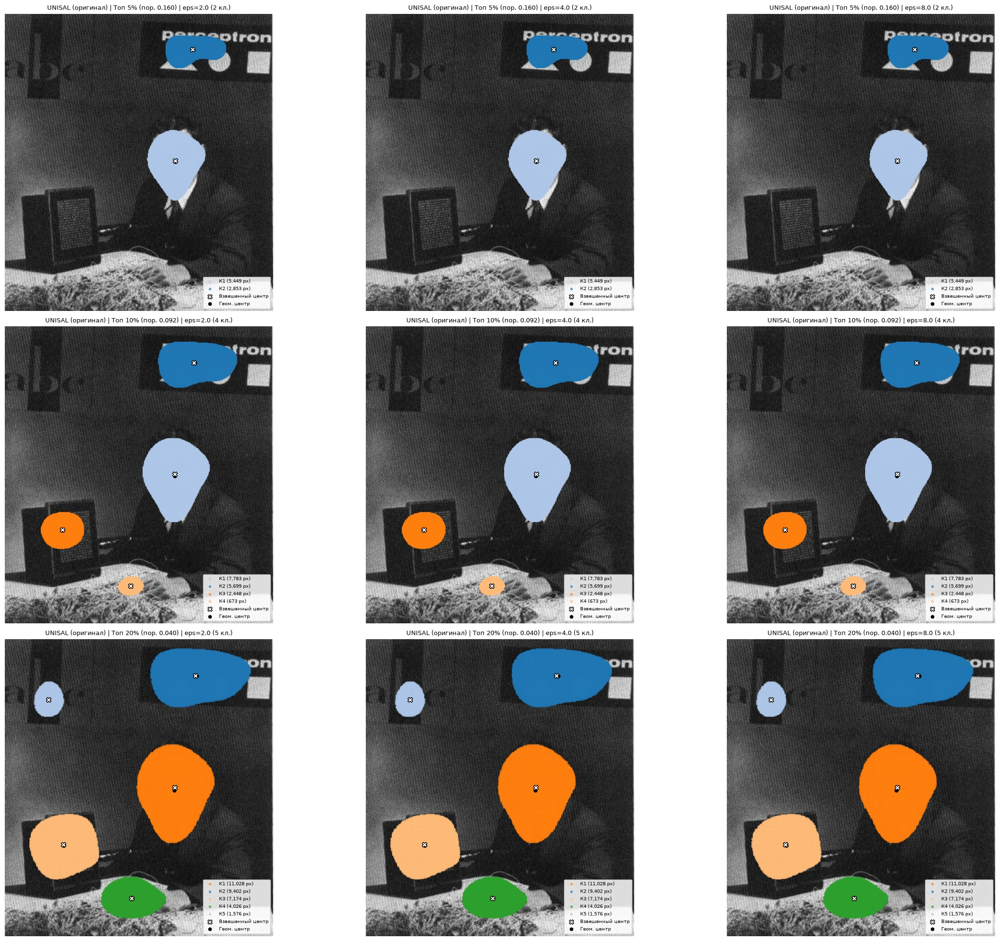

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (оригинал),5%,0.1597,2.0,2,8302,0,157721,"5,449, 2,853"
1,UNISAL (оригинал),5%,0.1597,4.0,2,8302,0,157721,"5,449, 2,853"
2,UNISAL (оригинал),5%,0.1597,8.0,2,8302,0,157721,"5,449, 2,853"
3,UNISAL (оригинал),10%,0.0918,2.0,4,16603,0,149420,"7,783, 5,699, 2,448, 673"
4,UNISAL (оригинал),10%,0.0918,4.0,4,16603,0,149420,"7,783, 5,699, 2,448, 673"
5,UNISAL (оригинал),10%,0.0918,8.0,4,16603,0,149420,"7,783, 5,699, 2,448, 673"
6,UNISAL (оригинал),20%,0.0405,2.0,5,33205,0,132818,"11,028, 9,402, 7,174, 4,026, 1,576"
7,UNISAL (оригинал),20%,0.0405,4.0,5,33205,0,132818,"11,028, 9,402, 7,174, 4,026, 1,576"
8,UNISAL (оригинал),20%,0.0405,8.0,5,33205,0,132818,"11,028, 9,402, 7,174, 4,026, 1,576"




UNISAL (ресайз 384x224) — Rosenblatt.jpg:


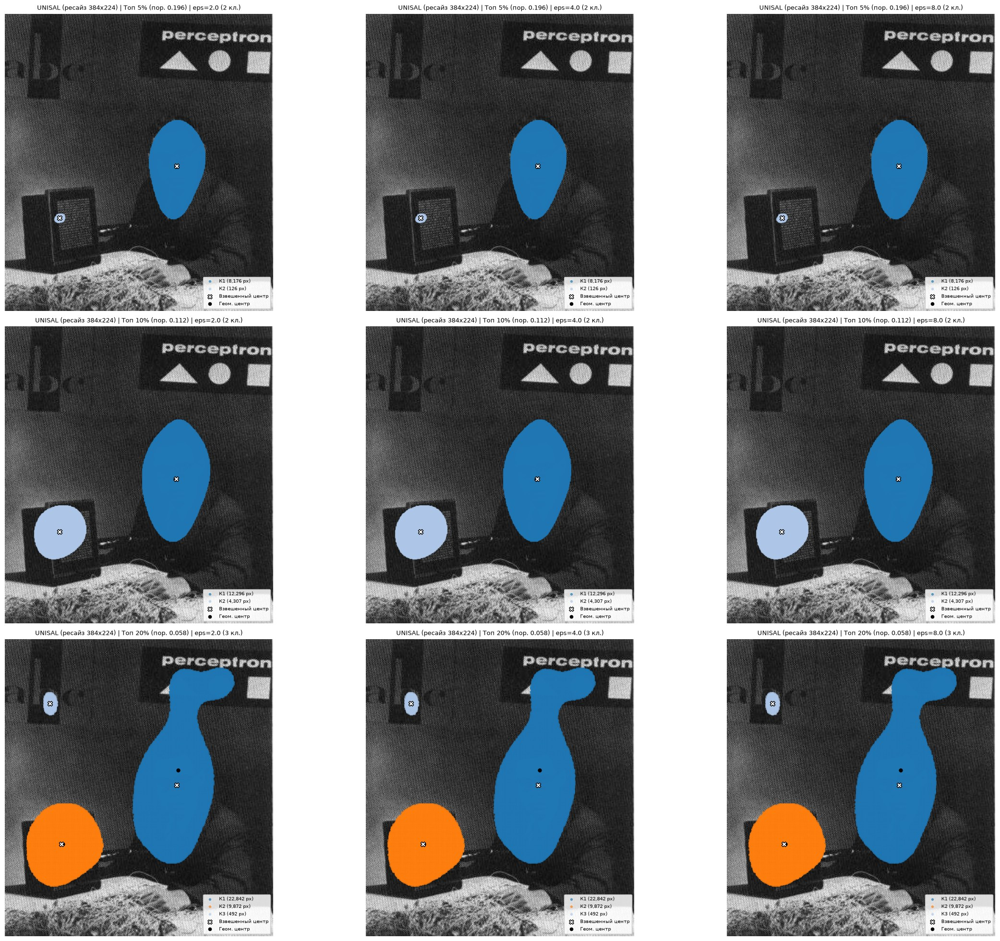

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (ресайз 384x224),5%,0.1964,2.0,2,8302,0,157721,"8,176, 126"
1,UNISAL (ресайз 384x224),5%,0.1964,4.0,2,8302,0,157721,"8,176, 126"
2,UNISAL (ресайз 384x224),5%,0.1964,8.0,2,8302,0,157721,"8,176, 126"
3,UNISAL (ресайз 384x224),10%,0.1115,2.0,2,16603,0,149420,"12,296, 4,307"
4,UNISAL (ресайз 384x224),10%,0.1115,4.0,2,16603,0,149420,"12,296, 4,307"
5,UNISAL (ресайз 384x224),10%,0.1115,8.0,2,16603,0,149420,"12,296, 4,307"
6,UNISAL (ресайз 384x224),20%,0.0577,2.0,3,33205,0,132818,"22,842, 9,872, 492"
7,UNISAL (ресайз 384x224),20%,0.0577,4.0,3,33205,0,132818,"22,842, 9,872, 492"
8,UNISAL (ресайз 384x224),20%,0.0577,8.0,3,33205,0,132818,"22,842, 9,872, 492"




DeepGaze IIE (оригинал) — Rosenblatt.jpg:


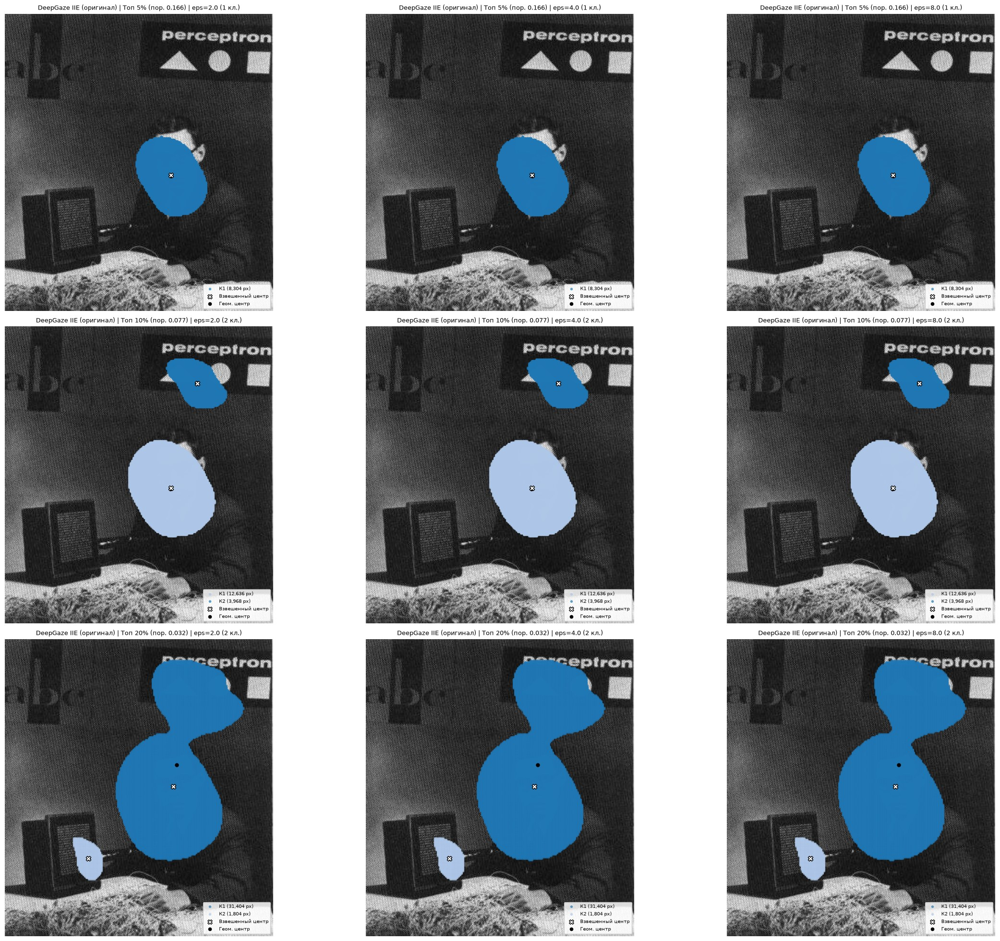

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,DeepGaze IIE (оригинал),5%,0.1658,2.0,1,8304,0,157719,"8,304"
1,DeepGaze IIE (оригинал),5%,0.1658,4.0,1,8304,0,157719,"8,304"
2,DeepGaze IIE (оригинал),5%,0.1658,8.0,1,8304,0,157719,"8,304"
3,DeepGaze IIE (оригинал),10%,0.0770,2.0,2,16604,0,149419,"12,636, 3,968"
4,DeepGaze IIE (оригинал),10%,0.0770,4.0,2,16604,0,149419,"12,636, 3,968"
5,DeepGaze IIE (оригинал),10%,0.0770,8.0,2,16604,0,149419,"12,636, 3,968"
6,DeepGaze IIE (оригинал),20%,0.0318,2.0,2,33208,0,132815,"31,404, 1,804"
7,DeepGaze IIE (оригинал),20%,0.0318,4.0,2,33208,0,132815,"31,404, 1,804"
8,DeepGaze IIE (оригинал),20%,0.0318,8.0,2,33208,0,132815,"31,404, 1,804"



Изображение: tiger.jpg | Разрешение: 736x1104 px (812,544 px)


UNISAL (оригинал) — tiger.jpg:


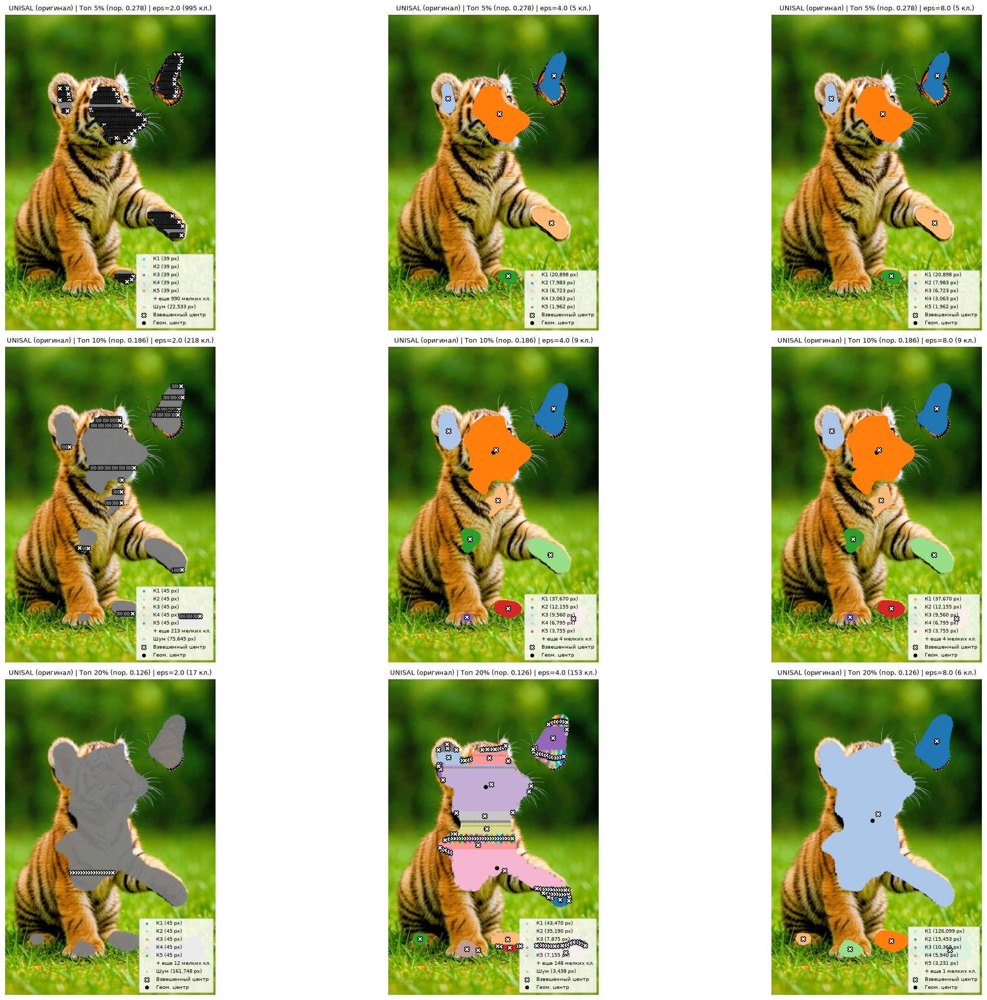

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (оригинал),5%,0.2780,2.0,995,18095,22533,771916,"39, 39, 39, 39, 39 ... (+990)"
1,UNISAL (оригинал),5%,0.2780,4.0,5,40628,0,771916,"20,898, 7,983, 6,723, 3,063, 1,962"
2,UNISAL (оригинал),5%,0.2780,8.0,5,40628,0,771916,"20,898, 7,983, 6,723, 3,063, 1,962"
3,UNISAL (оригинал),10%,0.1859,2.0,218,5610,75645,731289,"45, 45, 45, 45, 45 ... (+213)"
4,UNISAL (оригинал),10%,0.1859,4.0,9,81255,0,731289,"37,670, 12,155, 9,560, 6,795, 3,755 ... (+4)"
5,UNISAL (оригинал),10%,0.1859,8.0,9,81255,0,731289,"37,670, 12,155, 9,560, 6,795, 3,755 ... (+4)"
6,UNISAL (оригинал),20%,0.1262,2.0,17,761,161748,650035,"45, 45, 45, 45, 45 ... (+12)"
7,UNISAL (оригинал),20%,0.1262,4.0,153,159071,3438,650035,"43,470, 35,190, 7,875, 7,578, 7,155 ... (+148)"
8,UNISAL (оригинал),20%,0.1262,8.0,6,162509,0,650035,"126,099, 15,453, 10,368, 5,940, 3,231 ... (+1)"




UNISAL (ресайз 384x224) — tiger.jpg:


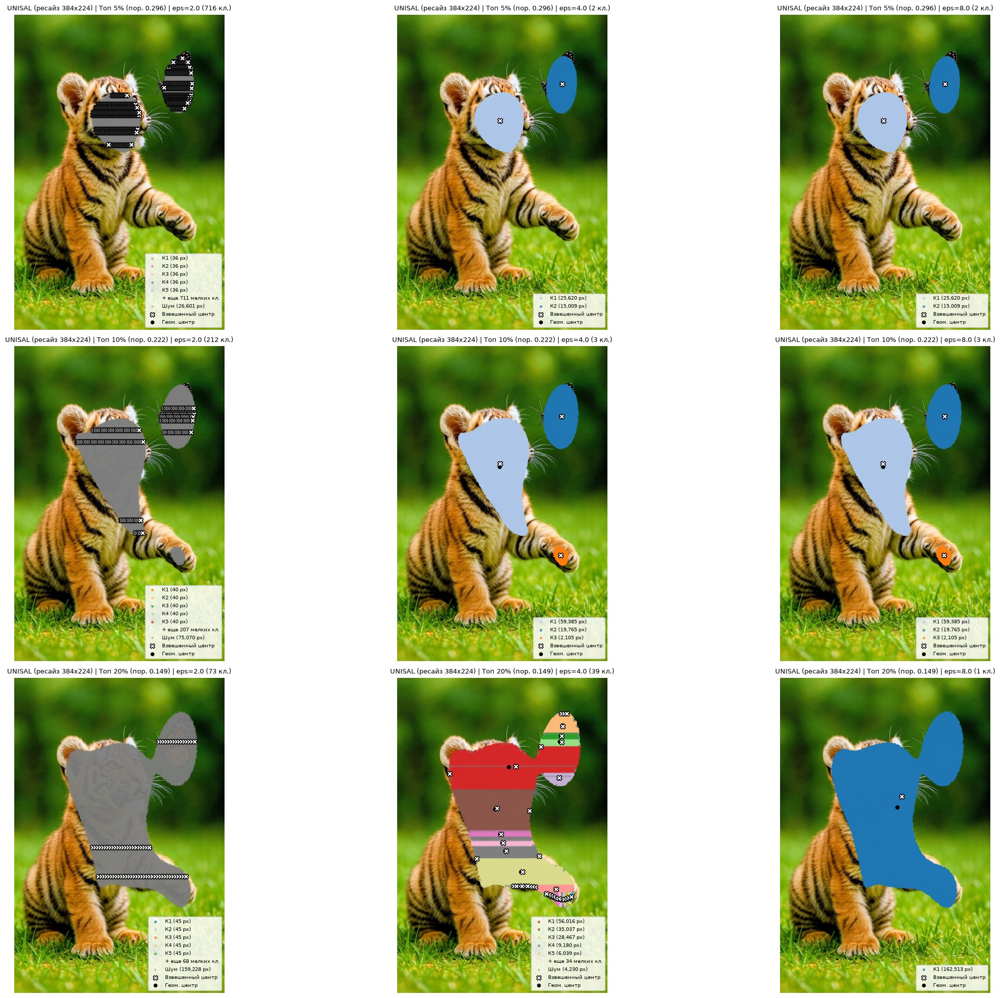

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,UNISAL (ресайз 384x224),5%,0.2957,2.0,716,14027,26601,771916,"36, 36, 36, 36, 36 ... (+711)"
1,UNISAL (ресайз 384x224),5%,0.2957,4.0,2,40628,0,771916,"25,620, 15,009"
2,UNISAL (ресайз 384x224),5%,0.2957,8.0,2,40628,0,771916,"25,620, 15,009"
3,UNISAL (ресайз 384x224),10%,0.2223,2.0,212,6185,75070,731289,"40, 40, 40, 40, 40 ... (+207)"
4,UNISAL (ресайз 384x224),10%,0.2223,4.0,3,81255,0,731289,"59,385, 19,765, 2,105"
5,UNISAL (ресайз 384x224),10%,0.2223,8.0,3,81255,0,731289,"59,385, 19,765, 2,105"
6,UNISAL (ресайз 384x224),20%,0.1487,2.0,73,3281,159228,650035,"45, 45, 45, 45, 45 ... (+68)"
7,UNISAL (ресайз 384x224),20%,0.1487,4.0,39,158279,4230,650035,"56,016, 35,037, 28,467, 9,180, 6,039 ... (+34)"
8,UNISAL (ресайз 384x224),20%,0.1487,8.0,1,162509,0,650035,"162,513"




DeepGaze IIE (оригинал) — tiger.jpg:


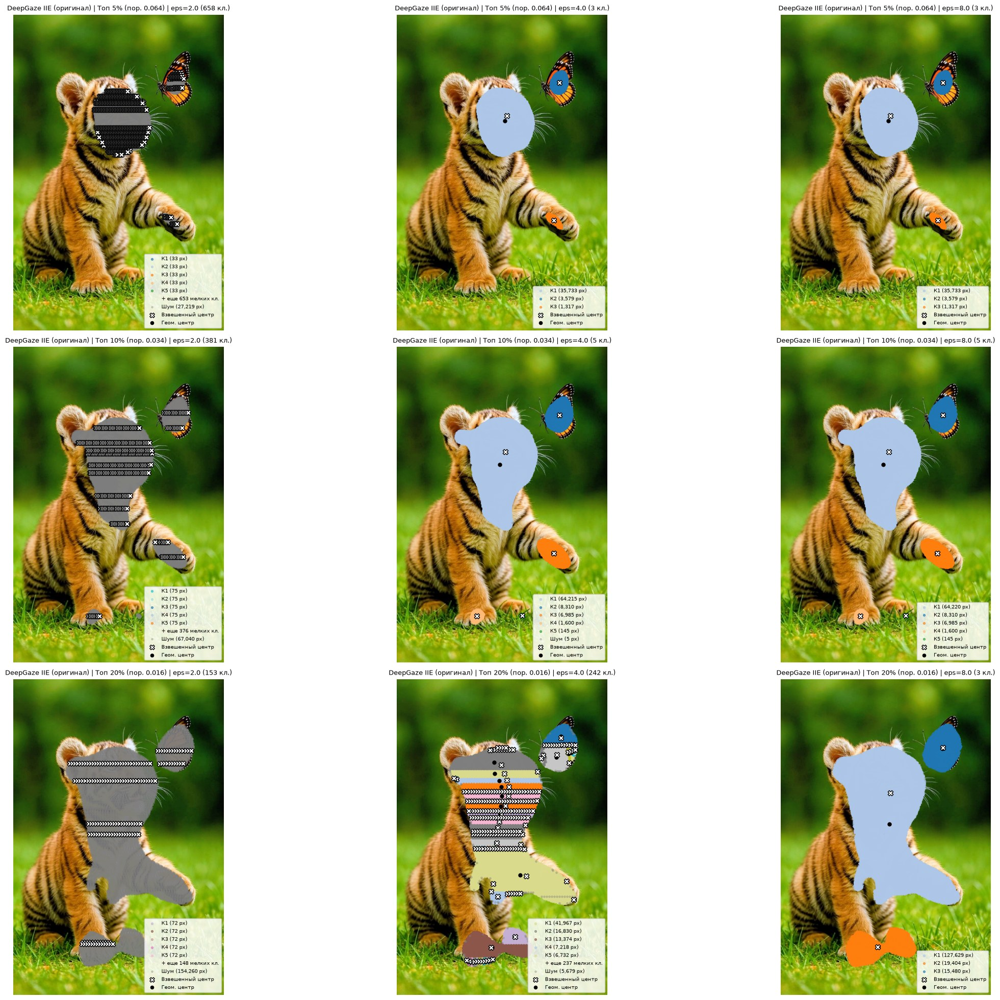

,Модель,Топ внимания,Порог,eps (px),Кластеров,Точек в кластерах,Шум,Фон (отсечено),Топ-5 размеров (px)
0,DeepGaze IIE (оригинал),5%,0.0640,2.0,658,13409,27219,771916,"33, 33, 33, 33, 33 ... (+653)"
1,DeepGaze IIE (оригинал),5%,0.0640,4.0,3,40628,0,771916,"35,733, 3,579, 1,317"
2,DeepGaze IIE (оригинал),5%,0.0640,8.0,3,40628,0,771916,"35,733, 3,579, 1,317"
3,DeepGaze IIE (оригинал),10%,0.0340,2.0,381,14216,67040,731288,"75, 75, 75, 75, 75 ... (+376)"
4,DeepGaze IIE (оригинал),10%,0.0340,4.0,5,81251,5,731288,"64,215, 8,310, 6,985, 1,600, 145"
5,DeepGaze IIE (оригинал),10%,0.0340,8.0,5,81256,0,731288,"64,220, 8,310, 6,985, 1,600, 145"
6,DeepGaze IIE (оригинал),20%,0.0163,2.0,153,8252,154260,650032,"72, 72, 72, 72, 72 ... (+148)"
7,DeepGaze IIE (оригинал),20%,0.0163,4.0,242,156833,5679,650032,"41,967, 16,830, 13,374, 7,218, 6,732 ... (+237)"
8,DeepGaze IIE (оригинал),20%,0.0163,8.0,3,162512,0,650032,"127,629, 19,404, 15,480"


In [10]:
for img_path in EXAMPLE_IMAGES:
    run_experiment_2(img_path)
